# imports

In [ ]:
import pandas as pd; import numpy as np ; import matplotlib.pyplot as plt ; import seaborn as sns;
from numpy import argmax;
import scipy.stats as st;

from sklearn.datasets import make_classification as mc;
from sklearn.datasets import make_regression as mr
from sklearn.datasets import load_iris;
from sklearn.datasets import load_diabetes

from sklearn.metrics import precision_recall_curve as prc;
from sklearn.metrics import roc_curve as roc;
from sklearn.metrics import classification_report as report;
from sklearn.metrics import roc_auc_score;
from sklearn.metrics import precision_score;
from sklearn.metrics import recall_score;
from sklearn.metrics import get_scorer_names
from sklearn.metrics import f1_score as f1
from sklearn.metrics import accuracy_score as accuracy
from sklearn.metrics import r2_score

from sklearn.linear_model import LogisticRegression as LR;
from sklearn.linear_model import LinearRegression as LinReg;
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import SGDClassifier as SGDC;

from sklearn.model_selection import train_test_split;
from sklearn.model_selection import cross_validate;
from sklearn.model_selection import KFold;
from sklearn.model_selection import LearningCurveDisplay
from sklearn.model_selection import RandomizedSearchCV as RSCV;
from sklearn.model_selection import LeavePOut;
from sklearn.model_selection import GridSearchCV as GSCV;

from sklearn.neighbors import KNeighborsRegressor as KNNR
from sklearn.neighbors import KNeighborsClassifier as KNNC

from sklearn.gaussian_process import GaussianProcessClassifier as GPC
from sklearn.gaussian_process.kernels import RBF

from sklearn.preprocessing import OneHotEncoder as OHE;
from sklearn.preprocessing import StandardScaler as SC;

from sklearn.ensemble import RandomForestClassifier as RFC;
from sklearn.ensemble import RandomForestRegressor as RFR;
from sklearn.ensemble import GradientBoostingClassifier as GBC
from sklearn.ensemble import ExtraTreesClassifier as ETC;
from sklearn.ensemble import ExtraTreesRegressor as ETR;
from sklearn.ensemble import AdaBoostClassifier as AdaBoost;
from sklearn.ensemble import AdaBoostRegressor;
from sklearn.ensemble import GradientBoostingRegressor as GBR;

from sklearn.tree import DecisionTreeClassifier as DTC;
from sklearn.tree import DecisionTreeRegressor  as DTR

from sklearn.naive_bayes import GaussianNB as GNB;

from sklearn.svm import SVC;
from sklearn.svm import SVR;

from sklearn.neural_network import MLPClassifier as MLPC
from sklearn.neural_network import MLPRegressor as MLPR;

from yellowbrick.classifier import ROCAUC;
from yellowbrick.classifier import PrecisionRecallCurve;

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA;

from yellowbrick.model_selection import LearningCurve

from sklearn.pipeline import make_pipeline;

from tqdm.notebook import tqdm

import warnings;warnings.simplefilter("ignore")

# ДЗ

## 1. При выполнении вертикального объединения убедитесь в отсутствии дубликатов данных.

In [ ]:
data1 = pd.read_csv('issues1.csv', index_col=0)
data2 = pd.read_csv('issues2.csv', index_col=0)
data3 = pd.read_csv('issues4.csv', index_col=0)
#display(data1.head())
#display(data2.head())
#display(data3.head())
data2 = data2.rename(columns={
    'channel_name': 'Channel',
    'Reported at': 'Issue_reported_Date',
    'Responded at': 'Issue_responded_Date',
    'Survey responded at': 'Survey_response_Date',
})
data3 = data3.rename(columns={
    'Unique id': 'Id',
    'channel_name': 'Channel',
    'Issue_reported at': 'Issue_reported_Date',
    'issue_responded': 'Issue_responded_Date',
    'Survey responded at': 'Survey_response_Date',
    'Agent': 'Agent_name'
})
data2['Issue_reported_Date'] = pd.to_datetime(data2['Issue_reported_Date'])
data2['Issue_responded_Date'] = pd.to_datetime(data2['Issue_responded_Date'])
data2['Survey_response_Date'] = pd.to_datetime(data2['Survey_response_Date'], format='%d %m %Y')
data1['Issue_reported_Date'] = pd.to_datetime(data1['Issue_reported_Date'], dayfirst=True)
data1['Issue_responded_Date'] = pd.to_datetime(data1['Issue_responded_Date'], dayfirst=True)
data1['Survey_response_Date'] = pd.to_datetime(data1['Survey_response_Date'], format='%d-%b-%y')
data3['Issue_reported_Date'] = pd.to_datetime(data3['Issue_reported_Date'])
data3['Issue_responded_Date'] = pd.to_datetime(data3['Issue_responded_Date'])
data3['Survey_response_Date'] = pd.to_datetime(data3['Survey_response_Date'])
data3['Agent_name'] = data3['Agent_name'].apply(
    lambda x: x.split()[0][0] + ". " + x.split()[1] if isinstance(x, str) else np.NAN
)
print(data1.shape, data2.shape, data3.shape)

#p=pd.concat([data1, data2, data3])
data_12 = pd.concat([data1, data2])
p = pd.concat([data_12, data3])

print("Полные дубликаты:", p.duplicated().sum())
# это проверит есть ли повторящиеся

(28425, 11) (44339, 10) (13143, 9)
Полные дубликаты: 0


## 2. При горизонтальной интеграции первой и второй таблицы выведите по каждому столбцу гистограмму распределения или плотность распределения, чтобы убедиться, что признаки выражаются по соотносимым шкалам.

,Id,Channel,category,Sub-category,Customer Remarks,Order_id,Issue_reported_Date,Issue_responded_Date,Survey_response_Date,Agent_name,CSAT Score
0,8c910188-c387-4a1b-8d90-24379ec8c047,Inbound,Returns,Reverse Pickup Enquiry,Very happy,NaN,2023-08-04 19:10:00,2023-08-04 19:13:00,2023-08-04,J. Blackwell,1
1,99d5ee06-8d2a-4754-bd17-ed235c70bf33,Inbound,Returns,Return request,Thoda jalfi replacement approve kijiye mera,89e6448f-9a48-4892-a09c-b47e0d8a87fe,2023-08-18 09:11:00,2023-08-18 09:18:00,2023-08-18,M. Wilson,4
2,336020c5-dc97-488f-8f16-ed33ed04e5fc,Inbound,Returns,Damaged,Technician not visit the RO and without visit ...,15476f9a-35cc-4f33-ae33-8d9cd6ecb1a6,2023-08-22 07:15:00,2023-08-22 08:15:00,2023-08-22,A. Smith,5
3,22c5643c-3d54-487c-8863-c57e198a70be,Inbound,Returns,Fraudulent User,madam ne mera problem solve kar Diya hai . t...,NaN,2023-08-14 09:21:00,2023-08-14 09:27:00,2023-08-14,A. Berry,5
4,abd330a8-f3e2-4b7a-b14a-4ed35c4ec023,Inbound,Returns,Fraudulent User,Gjjjzjxgxteuhxgxe5xhxh,NaN,2023-08-03 08:18:00,2023-08-03 08:23:00,2023-08-03,S. Taylor,5


,count
Channel,
Inbound,57464
Outcall,12594
Email,2706


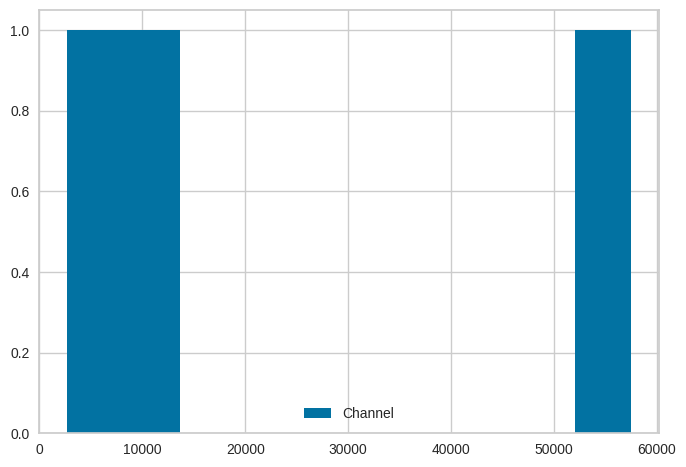

,count
category,
Returns,37212
Order Related,19943
Refund Related,3920
Product Queries,2968
Shopzilla Related,2290


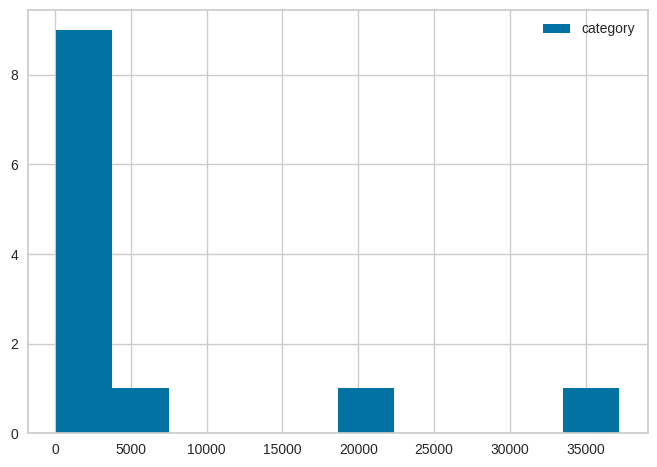

,count
Sub-category,
Reverse Pickup Enquiry,18780
Return request,7250
Delayed,6594
Order status enquiry,5974
Fraudulent User,3462


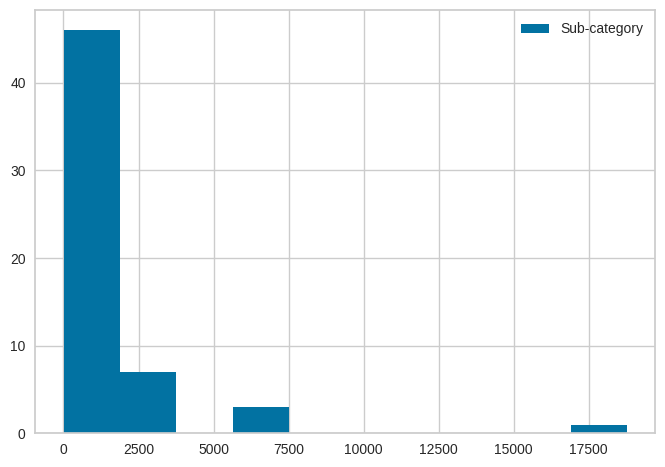

,count
Customer Remarks,
nan,44339
Good,1390
Good,1158
Very good,569
Nice,316


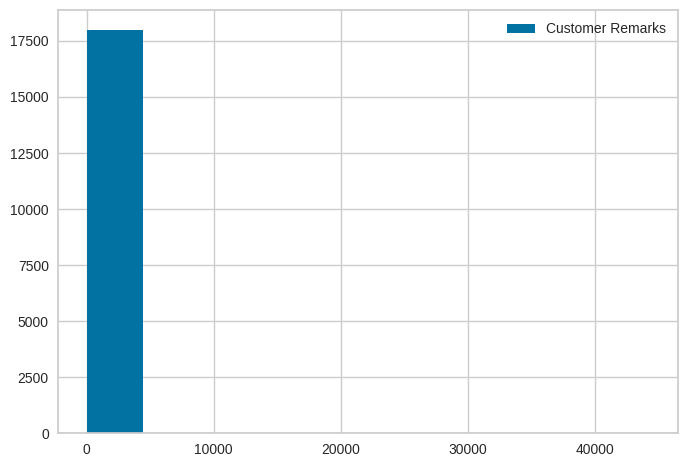

,count
Agent_name,
D. Smith,413
W. Taylor,364
J. Williams,354
J. Moore,269
M. Castillo,267


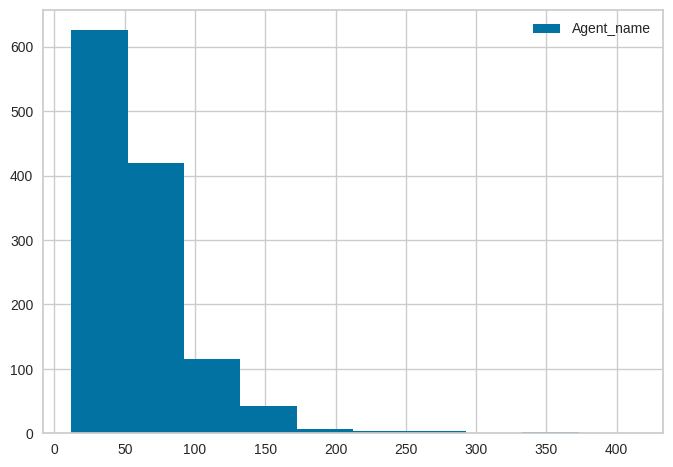

,count
CSAT Score,
5,50253
1,9995
4,9260
3,2163
2,1093


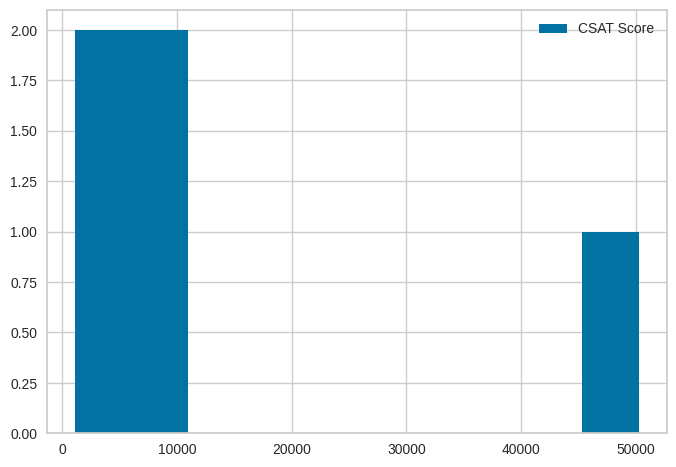

In [ ]:
 p2 = pd.concat([data1,data2])
 display(p2.head())
 cols = 'Channel;category;Sub-category;Customer Remarks;Agent_name;CSAT Score'.split(';')
 for i in cols:
  display(p2[i].apply(str).value_counts().head())
  plt.hist(p2[i].apply(str).value_counts(),label=i);plt.legend()
  #value_counts = p2[i].apply(str).value_counts()
  #plt.bar(value_counts.index, value_counts.values)
  plt.show()

##3. При выполнении третьего задания убедитесь более явно, что обильное количество пропущенных значений не является ошибкой объединения. Проведите больше, чем одну точечную проверку.

Прочитайте датасет с данными заказов клиентов, присоедините максимальное количество данных из него к датасету, получившемуся на предыдущем шаге.





Не найдено заказов: 69119






,0
Id,0
Channel,0
category,0
Sub-category,0
Customer Remarks,57482
Order_id,19246
Issue_reported_Date,0
Issue_responded_Date,0
Survey_response_Date,0
Agent_name,0


,0
Id,0
Channel,0
category,0
Sub-category,0
Customer Remarks,57482
Order_id,19246
Issue_reported_Date,0
Issue_responded_Date,0
Survey_response_Date,0
Agent_name,0


<Axes: >

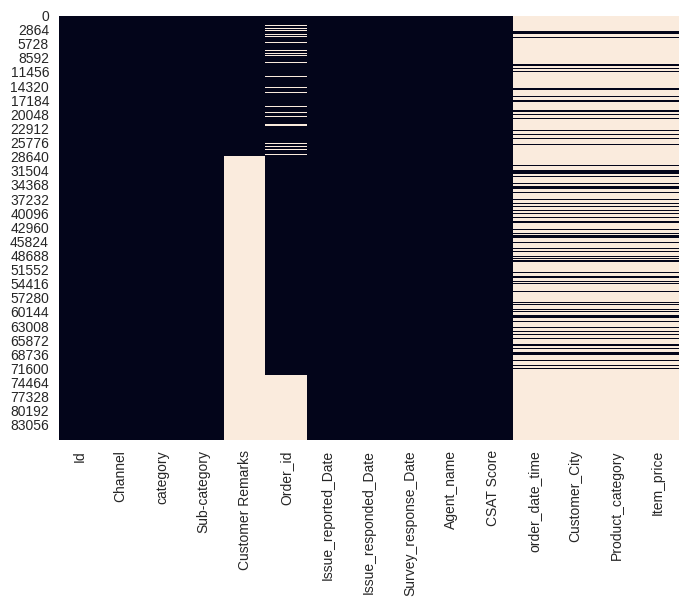

In [39]:
#[data1[i].isna().count() for i in data1]
orders_data = pd.read_csv('orders.csv', index_col=0)
orders_data = orders_data.rename(columns={
    'Id': 'Order_id',
})
#display(data1.isna().sum())
#display(data2.isna().sum())
#display(data3.isna().sum())
#display(orders_data.isna().sum())

print(f'\n\n\n')
missing_orders = orders_data[~orders_data['Order_id'][~orders_data['Order_id'].isna()].isin(p['Order_id'])]
print(f"Не найдено заказов: {len(missing_orders)}")
print(f'\n\n\n')


data_with_orders = p.merge(orders_data, on='Order_id', how='left')
display(p.isna().sum())
display(data_with_orders.isna().sum())
#заметим что NaN после объединения не больше количества не найденных заказов

sns.heatmap(data_with_orders.isna(), cbar=False)

,0
Id,0
Channel,0
category,0
Sub-category,0
Customer Remarks,57482
Order_id,19246
Issue_reported_Date,0
Issue_responded_Date,0
Survey_response_Date,0
Agent_name,0


##4. При выполнении третьего задания попробуйте использовать разные виды соединений. Как это отражается на структуре датасета?

Прочитайте датасет с данными заказов клиентов, присоедините максимальное количество данных из него к датасету, получившемуся на предыдущем шаге.

,Order_id,order_date_time,Customer_City,Product_category,Item_price
0,53465d50-a568-48a9-b96e-ee2a0524fee8,14/08/2023 18:54,NEW DELHI,Books & General merchandise,144.0
1,57d64c28-e3dc-49bd-8e8a-8e24572c6b59,30/07/2023 21:43,HAJIPUR,Home,445.0
2,55d4e1bb-e148-437f-aa83-3bfbae939155,10/07/2023 21:20,HYDERABAD,LifeStyle,399.0
3,509803e9-4c15-4db4-bbe7-fc1e12b6c6cc,08/08/2023 16:40,JASPUR,Mobile,32999.0
4,5cfbe41f-ffcc-4fcf-8520-94bb61dee14e,07/08/2023 08:29,JHAJJAR,Electronics,1499.0


,Id,Channel,category,Sub-category,Customer Remarks,Order_id,Issue_reported_Date,Issue_responded_Date,Survey_response_Date,Agent_name,CSAT Score,order_date_time,Customer_City,Product_category,Item_price
0,8c910188-c387-4a1b-8d90-24379ec8c047,Inbound,Returns,Reverse Pickup Enquiry,Very happy,NaN,2023-08-04 19:10:00,2023-08-04 19:13:00,2023-08-04,J. Blackwell,1,NaN,NaN,NaN,NaN
1,99d5ee06-8d2a-4754-bd17-ed235c70bf33,Inbound,Returns,Return request,Thoda jalfi replacement approve kijiye mera,89e6448f-9a48-4892-a09c-b47e0d8a87fe,2023-08-18 09:11:00,2023-08-18 09:18:00,2023-08-18,M. Wilson,4,14/08/2023 00:42,NAYAGARH,Electronics,1499.0
2,336020c5-dc97-488f-8f16-ed33ed04e5fc,Inbound,Returns,Damaged,Technician not visit the RO and without visit ...,15476f9a-35cc-4f33-ae33-8d9cd6ecb1a6,2023-08-22 07:15:00,2023-08-22 08:15:00,2023-08-22,A. Smith,5,NaN,NaN,NaN,NaN
3,22c5643c-3d54-487c-8863-c57e198a70be,Inbound,Returns,Fraudulent User,madam ne mera problem solve kar Diya hai . t...,NaN,2023-08-14 09:21:00,2023-08-14 09:27:00,2023-08-14,A. Berry,5,NaN,NaN,NaN,NaN
4,abd330a8-f3e2-4b7a-b14a-4ed35c4ec023,Inbound,Returns,Fraudulent User,Gjjjzjxgxteuhxgxe5xhxh,NaN,2023-08-03 08:18:00,2023-08-03 08:23:00,2023-08-03,S. Taylor,5,NaN,NaN,NaN,NaN


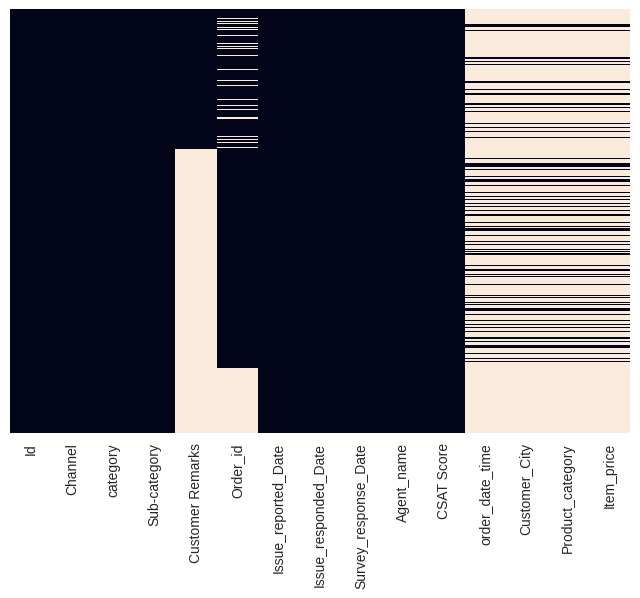

,Id,Channel,category,Sub-category,Customer Remarks,Order_id,Issue_reported_Date,Issue_responded_Date,Survey_response_Date,Agent_name,CSAT Score,order_date_time,Customer_City,Product_category,Item_price
0,NaN,NaN,NaN,NaN,NaN,53465d50-a568-48a9-b96e-ee2a0524fee8,NaT,NaT,NaT,NaN,NaN,14/08/2023 18:54,NEW DELHI,Books & General merchandise,144.0
1,NaN,NaN,NaN,NaN,NaN,57d64c28-e3dc-49bd-8e8a-8e24572c6b59,NaT,NaT,NaT,NaN,NaN,30/07/2023 21:43,HAJIPUR,Home,445.0
2,NaN,NaN,NaN,NaN,NaN,55d4e1bb-e148-437f-aa83-3bfbae939155,NaT,NaT,NaT,NaN,NaN,10/07/2023 21:20,HYDERABAD,LifeStyle,399.0
3,NaN,NaN,NaN,NaN,NaN,509803e9-4c15-4db4-bbe7-fc1e12b6c6cc,NaT,NaT,NaT,NaN,NaN,08/08/2023 16:40,JASPUR,Mobile,32999.0
4,NaN,NaN,NaN,NaN,NaN,5cfbe41f-ffcc-4fcf-8520-94bb61dee14e,NaT,NaT,NaT,NaN,NaN,07/08/2023 08:29,JHAJJAR,Electronics,1499.0


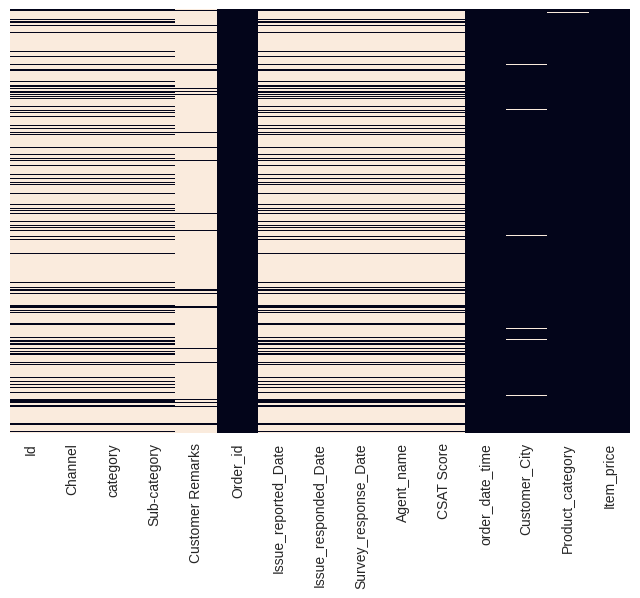

,Id,Channel,category,Sub-category,Customer Remarks,Order_id,Issue_reported_Date,Issue_responded_Date,Survey_response_Date,Agent_name,CSAT Score,order_date_time,Customer_City,Product_category,Item_price
0,07de89c4-2805-42f2-8f6c-8f5684e1db96,Inbound,Returns,Return request,NaN,0000a850-ca65-4eb1-ace1-9e34d5d1637a,2023-08-16 17:53:00,2023-08-16 17:56:00,2023-08-16,M. Edwards,5.0,06/08/2023 12:21,BIHARSHARIF,Electronics,999.0
1,7cffc115-5329-4682-910d-3a1c6fab0d3c,Inbound,Refund Related,Refund Enquiry,NaN,00014938-9dd7-4e15-a881-f4b1f1db30aa,2023-08-30 09:15:00,2023-08-30 09:23:00,2023-08-30,C. Gibson,5.0,NaN,NaN,NaN,NaN
2,5853545f-231b-410d-9c1e-1e283a7f26ca,Inbound,Order Related,Order status enquiry,NaN,0001b574-d0fb-4e9e-a261-0030fee22f85,2023-08-27 16:33:00,2023-08-27 16:34:00,2023-08-27,L. Patel,4.0,18/08/2023 13:27,PURNIA,Mobile,7299.0
3,28964e86-ebe7-4f44-9c0e-e41ede65bdbb,Inbound,Returns,Reverse Pickup Enquiry,NaN,0001de87-0dca-4ef4-93ae-4da06b1cd129,2023-08-24 07:43:00,2023-08-24 07:48:00,2023-08-24,K. Wilson,5.0,NaN,NaN,NaN,NaN
4,5dde1a0b-ff08-49d9-9b42-51cfcbbb046f,Inbound,Returns,Reverse Pickup Enquiry,NaN,00023baf-69b8-41fc-9d3d-40644a9ae409,2023-08-17 19:54:00,2023-08-17 20:21:00,2023-08-17,J. Moore,4.0,28/07/2023 07:04,BUDAUN,Books & General merchandise,185.0


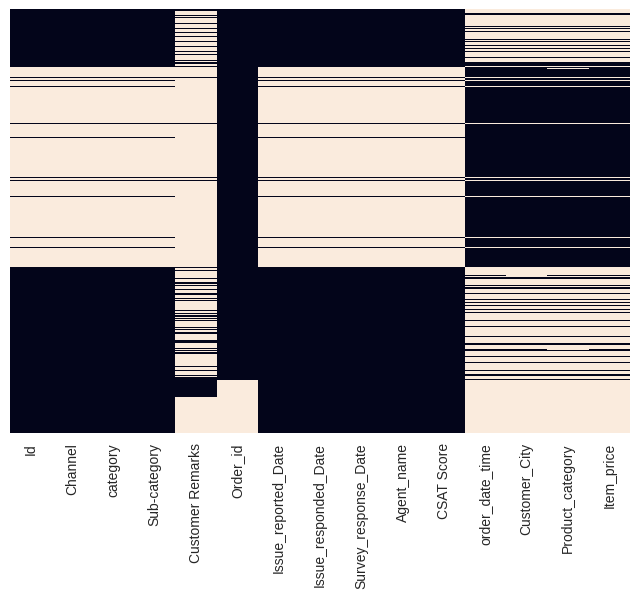

,Id,Channel,category,Sub-category,Customer Remarks,Order_id,Issue_reported_Date,Issue_responded_Date,Survey_response_Date,Agent_name,CSAT Score,order_date_time,Customer_City,Product_category,Item_price
0,99d5ee06-8d2a-4754-bd17-ed235c70bf33,Inbound,Returns,Return request,Thoda jalfi replacement approve kijiye mera,89e6448f-9a48-4892-a09c-b47e0d8a87fe,2023-08-18 09:11:00,2023-08-18 09:18:00,2023-08-18,M. Wilson,4,14/08/2023 00:42,NAYAGARH,Electronics,1499.0
1,9a9432e9-948b-4eaa-86fc-4c2ccb877fd0,Inbound,Order Related,Order status enquiry,Best,b922ec6e-d3d2-4522-be34-d8c89e45f4c4,2023-08-26 07:49:00,2023-08-26 07:57:00,2023-08-26,D. Perez,5,19/08/2023 06:55,SRINAGAR,Electronics,999.0
2,406d7a47-7dc6-4504-be9b-5ff044a7bb3a,Inbound,Order Related,Delayed,Change your delivery partner to some responsible,045e5c18-1211-4d5e-a7cd-c2af955c80d6,2023-08-24 14:55:00,2023-08-25 14:20:00,2023-08-25,S. Huber,1,17/08/2023 20:55,SURAT,Mobile,26935.0
3,a4365adc-b4cb-4de6-9a6d-9ca56d07030b,Inbound,Order Related,Delayed,Great effort,96db2a63-2d31-4a54-af49-d02dcc9efab0,2023-08-09 08:47:00,2023-08-09 12:20:00,2023-08-09,J. Gibson,5,29/07/2023 12:42,RAJOURI,Books & General merchandise,253.0
4,edddcc47-a99c-4fa2-8c36-3acb1361a98e,Inbound,Order Related,Priority delivery,Shopzilla customer care service was very good ...,15fe6fa0-07d1-4568-a78e-bb5760771d1e,2023-08-11 21:45:00,2023-08-11 21:48:00,2023-08-11,C. Crawford,5,10/08/2023 11:32,BHUJ,Books & General merchandise,96.0


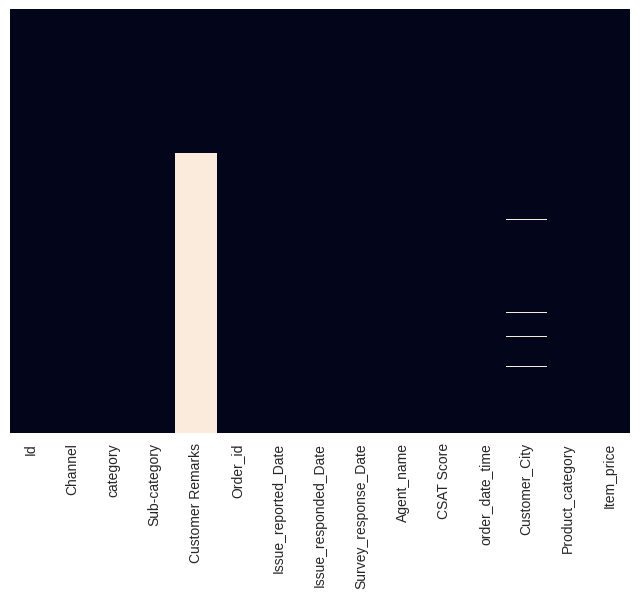

In [ ]:
orders_data = pd.read_csv('orders.csv', index_col=0)
orders_data = orders_data.rename(columns={
    'Id': 'Order_id',
})
display(orders_data.head())

data_with_orders = p.merge(orders_data, on='Order_id', how='left')
display(data_with_orders.head())
sns.heatmap(data_with_orders.isnull(), yticklabels=False, cbar=False);plt.show()
#все что нет в левом пропадает

data_with_orders = p.merge(orders_data, on='Order_id', how='right')
display(data_with_orders.head())
sns.heatmap(data_with_orders.isnull(), yticklabels=False, cbar=False);plt.show()
#все что нет в правом пропадает

data_with_orders = p.merge(orders_data, on='Order_id', how='outer')
display(data_with_orders.head())
sns.heatmap(data_with_orders.isnull(), yticklabels=False, cbar=False);plt.show()
#объединение

data_with_orders = p.merge(orders_data, on='Order_id', how='inner')
display(data_with_orders.head())
sns.heatmap(data_with_orders.isnull(), yticklabels=False, cbar=False);plt.show()
#пересечение по "on"


##5. Изучите документацию pandas в части описания методов merge и join.

merge позволяет соединять любые таблицы всеми возможными методами (how) по любым столбцам (on)

join это то же самое, что merge, только по индексам only.



##6. Познакомьтесь с форматом представления дат strftime.

%Y	Год (4 цифры)

%y	Год (2 цифры)

%m	Месяц (01–12)

%d	День (01–31)

%H	Час (00–23)

%M	Минуты (00–59)

%S	Секунды (00–59)

%A	День недели

%a	День недели

In [33]:
import datetime
now = datetime.datetime.now()
print(now)

#превратим в строку
s = now.strftime('%Y-%m-%d %H:%M:%S')
display(s)

#обратно
datetime.datetime.strptime(s, '%Y-%m-%d %H:%M:%S')

2025-04-10 18:50:26.032057


'2025-04-10 18:50:26'

datetime.datetime(2025, 4, 10, 18, 50, 26)